# Ji et al. 2020 — Cutaneous SCC
## 04 · Lineage-TF expression along the trajectory

Expression of an **early** (origin) vs **late** (terminus) transcriptional regulator overlaid on the linear manifold, showing the strongest-expressing cells so the two ends separate cleanly. Selected by pseudotime correlation: **KRT1** (cornified-envelope differentiation, high at the Gast/pSom-high origin) vs **SNAI2/SLUG** (the canonical EMT transcription factor, high at the basal/Crest-high terminus). The EMT-TF (SNAI2) marks the leading-edge end of the axis (Ji et al. 2020 TSK biology).

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_fig = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
pth_cb  = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name)

dataset: Ji2020_Skin-3


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
early_tf, late_tf = 'KRT1', 'SNAI2'
t = adata.obs['t'].values
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
for g in [early_tf, late_tf]:
    print('%s: pseudotime rho=%+.3f, pct expressing=%.2f' % (g, spearmanr(t,_vec(g))[0], (_vec(g)>0).mean()))

KRT1: pseudotime rho=-0.609, pct expressing=0.68
SNAI2: pseudotime rho=+0.341, pct expressing=0.51


### `expression.pdf` — early/late TF overlay (house categorical style)
Per-gene threshold = upper-quartile among expressing cells; abundant marker drawn first, sparse on top; grey = manifold. Early TF blue, late TF red.

overlay thresholds (upper quartile among expressers): {'KRT1': 3.873, 'SNAI2': 0.996} | cells shown: {'KRT1': 1166, 'SNAI2': 883}


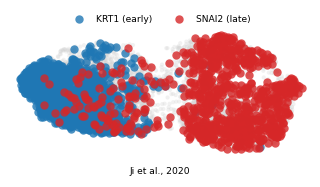

In [4]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray', title='')
for g in order:
    m = sel[g]; ax.scatter(xl[m,0], xl[m,1], s=30, c=colors[g], alpha=.8, linewidths=0,
                           label='%s (%s)' % (g, 'early' if g==early_tf else 'late'))
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py); ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values(): s.set_visible(False)
ax.legend(fontsize=6, frameon=False, loc='upper center', ncol=2, bbox_to_anchor=(.5,1.18))
ax.text(.5,-.14,'Ji et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],3) for g in [early_tf,late_tf]},
      '| cells shown:', {g:int(sel[g].sum()) for g in [early_tf,late_tf]})